<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/week4b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Seaborn EDA

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"TotalCharges unparsable -> NaN: {df['TotalCharges'].isna().sum()} rows")  # expect 11

# Helper to enforce Monday's finished-chart standard consistently
def finish(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

print(f"Loaded Telco Churn dataset: n = {len(df)} rows, {df.shape[1]} columns")


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TotalCharges unparsable -> NaN: 11 rows
Loaded Telco Churn dataset: n = 7043 rows, 21 columns


=== PART A: ONE DISTRIBUTION ===


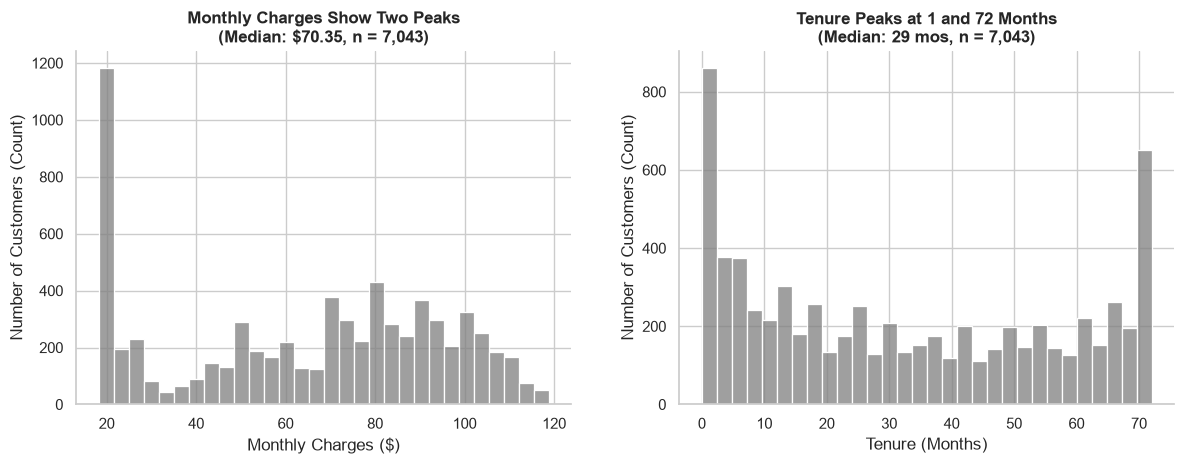

MonthlyCharges (n=7043) -> Median: $70.35 | Mean: $64.76 | Skew: -0.22
tenure (n=7043)         -> Median: 29.0 mos | Mean: 32.4 mos | Skew: 0.24


In [2]:
print("=== PART A: ONE DISTRIBUTION ===")

# --- ORIGINAL PREDICTIONS (DRILL 1 — UNEDITED) ---
# MonthlyCharges: Likely bimodal (two humps) — one large spike near $20 for basic phone-only plans and a broader hump around $70–$100 for fiber-optic/bundled plans; moderately right-skewed or spread out.
# Result check: Predicted bimodal and moderately right-skewed; actual bimodal with mild negative skew (-0.22, median $70.35 > mean $64.76) because the large upper hump sits above the midpoint.
# tenure: Likely bimodal (two humps) with spikes at both ends — many new customers at 1–5 months and a large loyal cohort clustered near the 72-month cap; roughly U-shaped rather than bell-shaped.
# Result check: Predicted bimodal U-shape with spikes at both ends; actual bimodal U-shape with spikes at 1 and 72 months and mild positive skew (0.24).

n_mc = df['MonthlyCharges'].notna().sum()
n_ten = df['tenure'].notna().sum()
mc_med = df['MonthlyCharges'].median()
ten_med = df['tenure'].median()
ten_max = int(df['tenure'].max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: MonthlyCharges
sns.histplot(data=df, x='MonthlyCharges', bins=30, color='#7f7f7f', ax=axes[0])
finish(axes[0], f'Monthly Charges Show Two Peaks\n(Median: \\${mc_med:.2f}, n = {n_mc:,})', 'Monthly Charges ($)', 'Number of Customers (Count)')

# Right: tenure
sns.histplot(data=df, x='tenure', bins=30, color='#7f7f7f', ax=axes[1])
finish(axes[1], f'Tenure Peaks at 1 and {ten_max} Months\n(Median: {ten_med:.0f} mos, n = {n_ten:,})', 'Tenure (Months)', 'Number of Customers (Count)')

fig.tight_layout(w_pad=3.0)
plt.show()

print(f"MonthlyCharges (n={n_mc}) -> Median: ${mc_med:.2f} | Mean: ${df['MonthlyCharges'].mean():.2f} | Skew: {df['MonthlyCharges'].skew():.2f}")
print(f"tenure (n={n_ten})         -> Median: {ten_med:.1f} mos | Mean: {df['tenure'].mean():.1f} mos | Skew: {df['tenure'].skew():.2f}")

# Honest reading lines (n = 7,043):
# - MonthlyCharges (n = 7,043): Bimodal distribution with a sharp spike near $20 and a broad peak around $70–$95 (median $70.35, skew -0.22), showing two distinct pricing tiers rather than a single bell curve.
# - tenure (n = 7,043): Bimodal U-shaped distribution with heavy spikes at 1 month and 72 months (median 29.0 months, skew 0.24), reflecting high early churn alongside a large long-term subscriber base.


=== PART B: COMPARING GROUPS ===


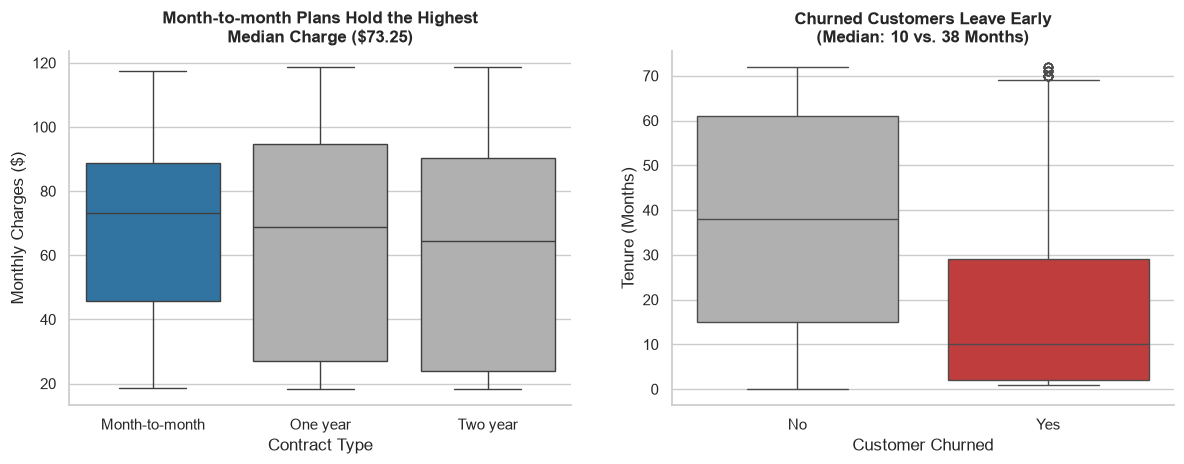

Median MonthlyCharges by Contract:
Contract
Month-to-month    73.25
One year          68.75
Two year          64.35
Name: MonthlyCharges, dtype: float64

Tenure Median & IQR by Churn:
       median    q1    q3   iqr
Churn                          
No       38.0  15.0  61.0  46.0
Yes      10.0   2.0  29.0  27.0


In [3]:
print("=== PART B: COMPARING GROUPS ===")

# --- ORIGINAL PREDICTIONS (DRILLS 2 & 3 — UNEDITED) ---
# Drill 2 (MonthlyCharges by Contract): Two-year contracts will have the highest median monthly charge because bundled multi-service subscribers commit to longer terms, while Month-to-month will sit lower.
# Result check: Predicted Two year would have the highest median; actual Month-to-month is highest ($73.25) and Two year is lowest ($64.35).
# Drill 3 (tenure by Churn): Churned customers ('Yes') will have a much shorter median tenure than retained customers ('No'), since customers who leave tend to cancel early in their lifecycle.
# Result check: Predicted shorter median tenure for churned customers; actual median tenure is 10.0 months for Churn='Yes' vs. 38.0 months for Churn='No'.

contract_order = ['Month-to-month', 'One year', 'Two year']
mc_by_contract = df.groupby('Contract')['MonthlyCharges'].median()
tenure_by_churn = df.groupby('Churn')['tenure'].median()

top_contract = mc_by_contract.idxmax()
top_contract_med = mc_by_contract.max()
churn_med = tenure_by_churn['Yes']
retain_med = tenure_by_churn['No']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: MonthlyCharges by Contract
palette_contract = ['#1f77b4', '#b0b0b0', '#b0b0b0']
sns.boxplot(data=df, x='Contract', y='MonthlyCharges', order=contract_order, palette=palette_contract, hue='Contract', legend=False, ax=axes[0])
finish(axes[0], f'{top_contract} Plans Hold the Highest\nMedian Charge (\\${top_contract_med:.2f})', 'Contract Type', 'Monthly Charges ($)')

# Right: tenure by Churn
palette_churn = ['#b0b0b0', '#d62728']
sns.boxplot(data=df, x='Churn', y='tenure', order=['No', 'Yes'], palette=palette_churn, hue='Churn', legend=False, ax=axes[1])
finish(axes[1], f'Churned Customers Leave Early\n(Median: {churn_med:.0f} vs. {retain_med:.0f} Months)', 'Customer Churned', 'Tenure (Months)')

fig.tight_layout(w_pad=3.0)
plt.show()

print("Median MonthlyCharges by Contract:")
print(mc_by_contract.round(2))

tenure_stats = df.groupby('Churn')['tenure'].agg(
    median='median',
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
    iqr=lambda s: s.quantile(0.75) - s.quantile(0.25)
)
print("\nTenure Median & IQR by Churn:")
print(tenure_stats)

# Written readings grounded in printed values:
# - Drill 2 note: Month-to-month has the highest median ($73.25), while Two-year ($64.35) sits noticeably lower. This aligns with our Module 2 InternetService × Contract crosstab, which showed that customers without internet service (low-cost phone-only plans) were far more likely to hold Two-year contracts than higher-priced Fiber optic users.
# - Drill 3 note: Retained customers ('No') have a median tenure of 38.0 months (IQR 46.0, from 15.0 to 61.0), whereas churned customers ('Yes') have a median tenure of 10.0 months (IQR 27.0, from 2.0 to 29.0).


=== PART C: CATEGORIES AND RATES ===


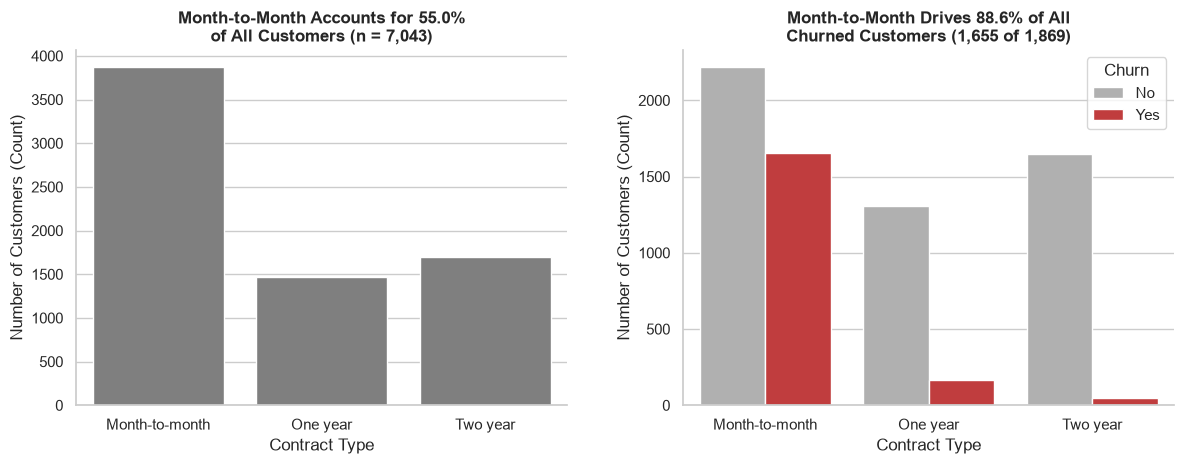

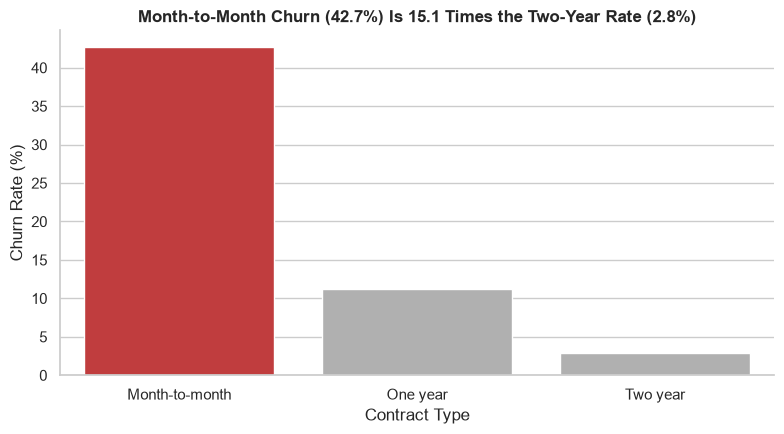

Exact Churn Rates (%):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: churn_flag, dtype: float64


In [4]:
print("=== PART C: CATEGORIES AND RATES ===")

# --- ORIGINAL PREDICTION (DRILL 5 — UNEDITED) ---
# Churn rate order: Month-to-month will have the highest churn rate, followed by One year, and Two year will have the lowest churn rate because early-termination barriers keep contracted users from leaving.
# Result check: Predicted order Month-to-month > One year > Two year; actual churn rates match at 42.71% > 11.27% > 2.83%.

# Define the missing churn_flag column
df['churn_flag'] = (df['Churn'] == 'Yes').astype(int)

mtm_share = (df['Contract'] == 'Month-to-month').mean() * 100
mtm_churn_count = ((df['Contract'] == 'Month-to-month') & (df['Churn'] == 'Yes')).sum()
total_churn_count = (df['Churn'] == 'Yes').sum()
mtm_churn_share = (mtm_churn_count / total_churn_count) * 100

# 1. Countplots (overall vs split by Churn)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

sns.countplot(data=df, x='Contract', order=contract_order, color='#7f7f7f', ax=axes[0])
finish(axes[0], f'Month-to-Month Accounts for {mtm_share:.1f}%\nof All Customers (n = {len(df):,})', 'Contract Type', 'Number of Customers (Count)')

sns.countplot(data=df, x='Contract', hue='Churn', order=contract_order, hue_order=['No', 'Yes'], palette=['#b0b0b0', '#d62728'], ax=axes[1])
finish(axes[1], f'Month-to-Month Drives {mtm_churn_share:.1f}% of All\nChurned Customers ({mtm_churn_count:,} of {total_churn_count:,})', 'Contract Type', 'Number of Customers (Count)')

fig.tight_layout(w_pad=3.0)
plt.show()

# Specific count chart note:
# Month-to-month is both the largest customer group (55.0% of the base) and the highest-risk tier, so a raw count chart cannot separate group size from churn risk—whereas the rate barplot below isolates the true churn rate (42.7% vs. 2.8%).

# 2. Barplot of Churn Rate (mean of churn_flag) with clean phrasing
rates = df.groupby('Contract')['churn_flag'].mean() * 100
mtm_rate = rates['Month-to-month']
two_yr_rate = rates['Two year']
ratio = mtm_rate / two_yr_rate

rate_title = f"Month-to-Month Churn ({mtm_rate:.1f}%) Is {ratio:.1f} Times the Two-Year Rate ({two_yr_rate:.1f}%)"

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=df, x='Contract', y='churn_flag', order=contract_order,
    estimator=lambda x: np.mean(x) * 100, errorbar=None,
    palette=['#d62728', '#b0b0b0', '#b0b0b0'], hue='Contract', legend=False, ax=ax
)
finish(ax, rate_title, 'Contract Type', 'Churn Rate (%)')
fig.tight_layout()
plt.show()

print("Exact Churn Rates (%):")
print(rates.round(2))

=== PART D: RELATIONSHIPS ===


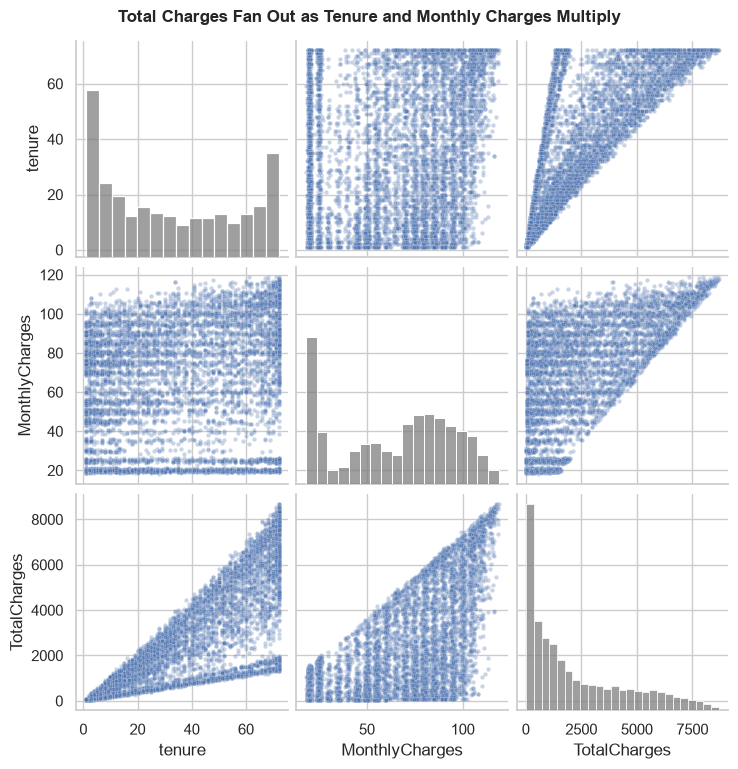

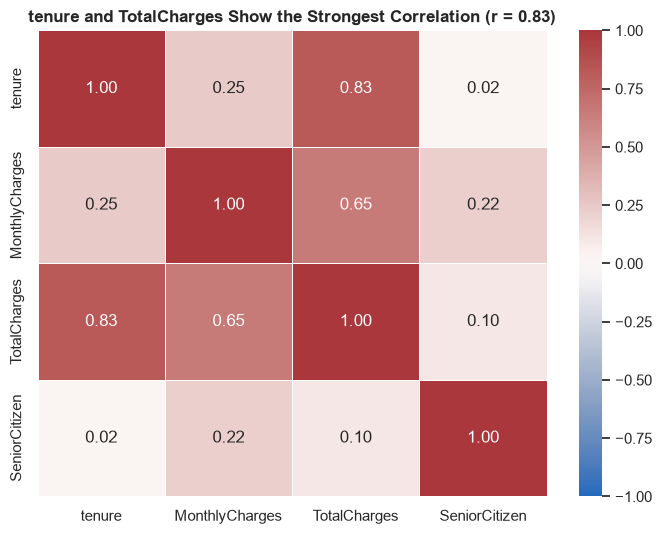

Correlation Matrix:
                tenure  MonthlyCharges  TotalCharges  SeniorCitizen
tenure           1.000           0.248         0.826          0.017
MonthlyCharges   0.248           1.000         0.651          0.220
TotalCharges     0.826           0.651         1.000          0.102
SeniorCitizen    0.017           0.220         0.102          1.000


In [5]:
print("=== PART D: RELATIONSHIPS ===")

# --- ORIGINAL PREDICTIONS (DRILLS 6 & 7 — UNEDITED) ---
# Drill 6 (Pairplot): 'tenure' and 'TotalCharges' will look most linearly related because total charges accumulate over time as monthly bills add up each month.
# Result check: Predicted tenure and TotalCharges would show the clearest linear trend; actual pairplot confirms a strong upward linear fan between tenure and TotalCharges.
# Drill 7 (Heatmap): ('tenure', 'TotalCharges') will be the strongest correlation pair for the same cumulative billing reason.
# Result check: Predicted ('tenure', 'TotalCharges') would be strongest; actual matrix confirms ('tenure', 'TotalCharges') is highest at r = 0.83.

# 1. Pairplot
g = sns.pairplot(df[['tenure', 'MonthlyCharges', 'TotalCharges']].dropna(), plot_kws={'alpha': 0.3, 's': 10}, diag_kws={'color': '#7f7f7f'})
g.fig.suptitle('Total Charges Fan Out as Tenure and Monthly Charges Multiply', y=1.02, fontsize=12, fontweight='bold')
plt.show()

# Pairplot observations (Drill 6):
# - Diagonal cells: Show the univariate histogram distribution of each individual variable (tenure, MonthlyCharges, and TotalCharges).
# - Off-diagonal pattern: The scatter between tenure and TotalCharges forms a distinct triangular fan/cone shape—at any given tenure, TotalCharges spreads between a lower boundary (basic low-rate plans) and an upper boundary (high-rate bundled plans).

# 2. Correlation Heatmap (strongest pair computed dynamically from matrix)
corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
corr_mat = df[corr_cols].corr()

pairs = corr_mat.where(np.triu(np.ones(corr_mat.shape, dtype=bool), k=1)).stack()
best_pair = pairs.abs().idxmax()
best_r = pairs[best_pair]
heatmap_title = f'{best_pair[0]} and {best_pair[1]} Show the Strongest Correlation (r = {best_r:.2f})'

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title(heatmap_title, fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

print("Correlation Matrix:")
print(corr_mat.round(3))

# Heatmap notes (Drill 7):
# - Why ('tenure', 'TotalCharges') is strong: TotalCharges is mathematically derived from cumulative billing (roughly tenure * MonthlyCharges), creating built-in structural collinearity (r = 0.83).
# - Caution on correlation: Correlation measures only linear association between variables—it does not establish cause and effect, and can be inflated when one column is mechanically constructed from another.


=== PART E: CHALLENGE ===


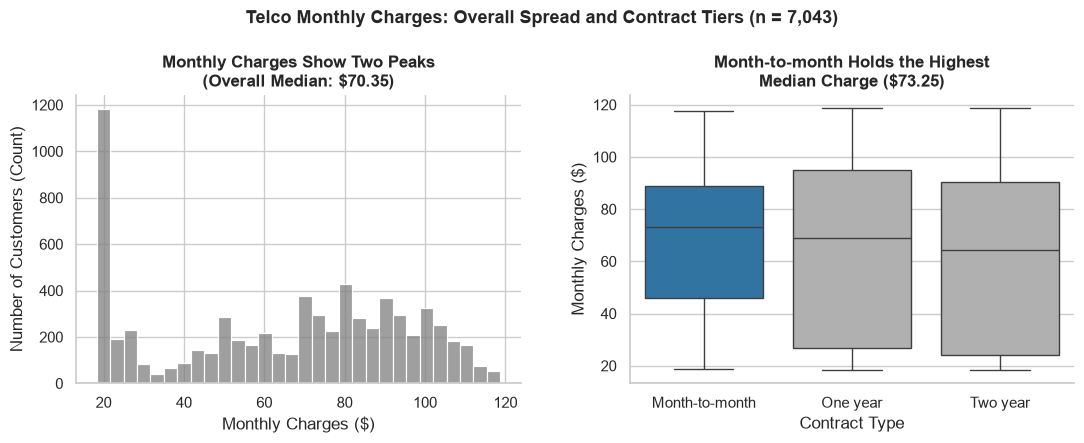

In [6]:
print("=== PART E: CHALLENGE ===")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left Panel: Histogram of MonthlyCharges (reusing computed Part A wording)
sns.histplot(data=df, x='MonthlyCharges', bins=30, color='#7f7f7f', ax=axes[0])
finish(axes[0], f'Monthly Charges Show Two Peaks\n(Overall Median: \\${mc_med:.2f})', 'Monthly Charges ($)', 'Number of Customers (Count)')

# Right Panel: Boxplot of MonthlyCharges by Contract
sns.boxplot(
    data=df, x='Contract', y='MonthlyCharges', order=contract_order,
    palette=['#1f77b4', '#b0b0b0', '#b0b0b0'], hue='Contract', legend=False, ax=axes[1]
)
finish(axes[1], f'{top_contract} Holds the Highest\nMedian Charge (\\${top_contract_med:.2f})', 'Contract Type', 'Monthly Charges ($)')

fig.suptitle(f'Telco Monthly Charges: Overall Spread and Contract Tiers (n = {n_mc:,})', fontsize=13, fontweight='bold')
fig.tight_layout(w_pad=3.0)
fig.savefig('telco_monthly_charges_eda.png', dpi=200)
plt.show()
